# Checkpoint — KMeans & DBSCAN

Dit notebook wordt automatisch gecheckt via pytest (GitHub Actions). De checks voeren je notebook uit en valideren of bepaalde variabelen bestaan en binnen de verwachte ranges vallen. **Je krijgt geen hints in de foutmeldingen: het is aan jou om correct werkende code te schrijven.**

## BELANGRIJK: gebruik exact de genoemde variabelennamen

De checks zoeken volgende variabelen in je notebook. Andere namen worden niet gezien:

- `best_k_wine` — de gekozen waarde van k voor de Wine-dataset (int)
- `silhouette_wine` — de silhouette score van die keuze (float)
- `image` — de ingeladen afbeelding (3D numpy-array)
- `n_colors` — het tuple van aantal kleuren `(10, 8, 6, 4, 2)`
- `segmented_imgs` — de lijst van gesegmenteerde afbeeldingen (5 elementen, zelfde vorm als `image`)
- `best_k_iris` — de gekozen waarde van k voor de Iris-dataset (int)
- `silhouette_iris` — de silhouette score van die keuze (float)
- `best_k_mall` — de gekozen waarde van k voor de Mall-dataset (int)
- `silhouette_mall` — de silhouette score van die keuze (float)
- `antwoord_iris` — meerkeuzevraag 1: `"A"`, `"B"`, `"C"` of `"D"`
- `antwoord_dbscan` — meerkeuzevraag 2: `"A"`, `"B"`, `"C"` of `"D"`

Gebruik overal `random_state=42` (en `n_init=10`) bij KMeans zodat je resultaten reproduceerbaar zijn en binnen de verwachte drempels vallen. Werk met de lokale afbeelding `images/butterfly.jpg` (er wordt niets gedownload).

## Oefening 1 — Wijn

Cluster de Wine-dataset zo optimaal mogelijk met KMeans. De dataset heeft 13 features op verschillende schalen, dus **schaal eerst met `StandardScaler`**.

Probeer verschillende waarden van `k`, bereken telkens de **silhouette score** en kies de `k` met de hoogste score.

Bewaar je keuze in `best_k_wine` en de bijhorende score in `silhouette_wine`.

In [9]:
import numpy as np
from sklearn import datasets
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score


wine = datasets.load_wine()
data = wine.data

# Schaal de data zodat alle features gelijk gewicht krijgen
scaler = StandardScaler()
data_scaled = scaler.fit_transform(data)

In [10]:
# TODO: bereken voor elke k in range(2, 8) de silhouette score (KMeans met
# random_state=42, n_init=10). Bewaar de k met de hoogste score in best_k_wine
# en die score in silhouette_wine.
startwaarde = -1
for k in range(2,8):    
    kmeans = KMeans(n_clusters=k,random_state=42,n_init=10)
    k_means_label = kmeans.fit_predict(data_scaled)
    score = silhouette_score(data_scaled, kmeans.labels_)
    if score > startwaarde:
        best_k_wine = k
        
        silhouette_wine = score
        startwaarde = score 
        print(f"bij k = {k} is de silhouette score {silhouette_wine}")


print("Beste k:", best_k_wine)
print("Beste silhouette score:", silhouette_wine)

bij k = 2 is de silhouette score 0.2593169555318255
bij k = 3 is de silhouette score 0.2848589191898987
Beste k: 3
Beste silhouette score: 0.2848589191898987


## Oefening 2 — Image Segmentation

We gebruiken clustering om een afbeelding in stukken met gelijkaardige kleuren te verdelen. Gebruik de lokale afbeelding `images/butterfly.jpg` (533×800 pixels, 3 kleurkanalen).

Hervorm de 3D-array tot een `(n_pixels, 3)` matrix met `reshape(-1, 3)`, train dan KMeans met `n_clusters` in `(10, 8, 6, 4, 2)` en vervang elke pixel door de centroidkleur van zijn cluster. Hervorm het resultaat terug naar de originele vorm.

Bewaar het tuple `n_colors = (10, 8, 6, 4, 2)` en de 5 gesegmenteerde afbeeldingen in `segmented_imgs`.

In [36]:
import numpy as np
from PIL import Image
from sklearn.cluster import KMeans
import cv2
import matplotlib.pyplot as plt

# Gebruik het lokale voorbeeldbeeld (geen download nodig)
image = np.asarray(Image.open('/workspaces/ML-Algo-student-main/exercises_with_checks/week06/images/pauw.jpg'))
print('image shape:', image.shape)

# Hervorm de 3D-array (pixels, breedte, kanalen) naar een (n_pixels, 3) matrix
X = image.reshape(-1, 3)

image shape: (1266, 1900, 3)


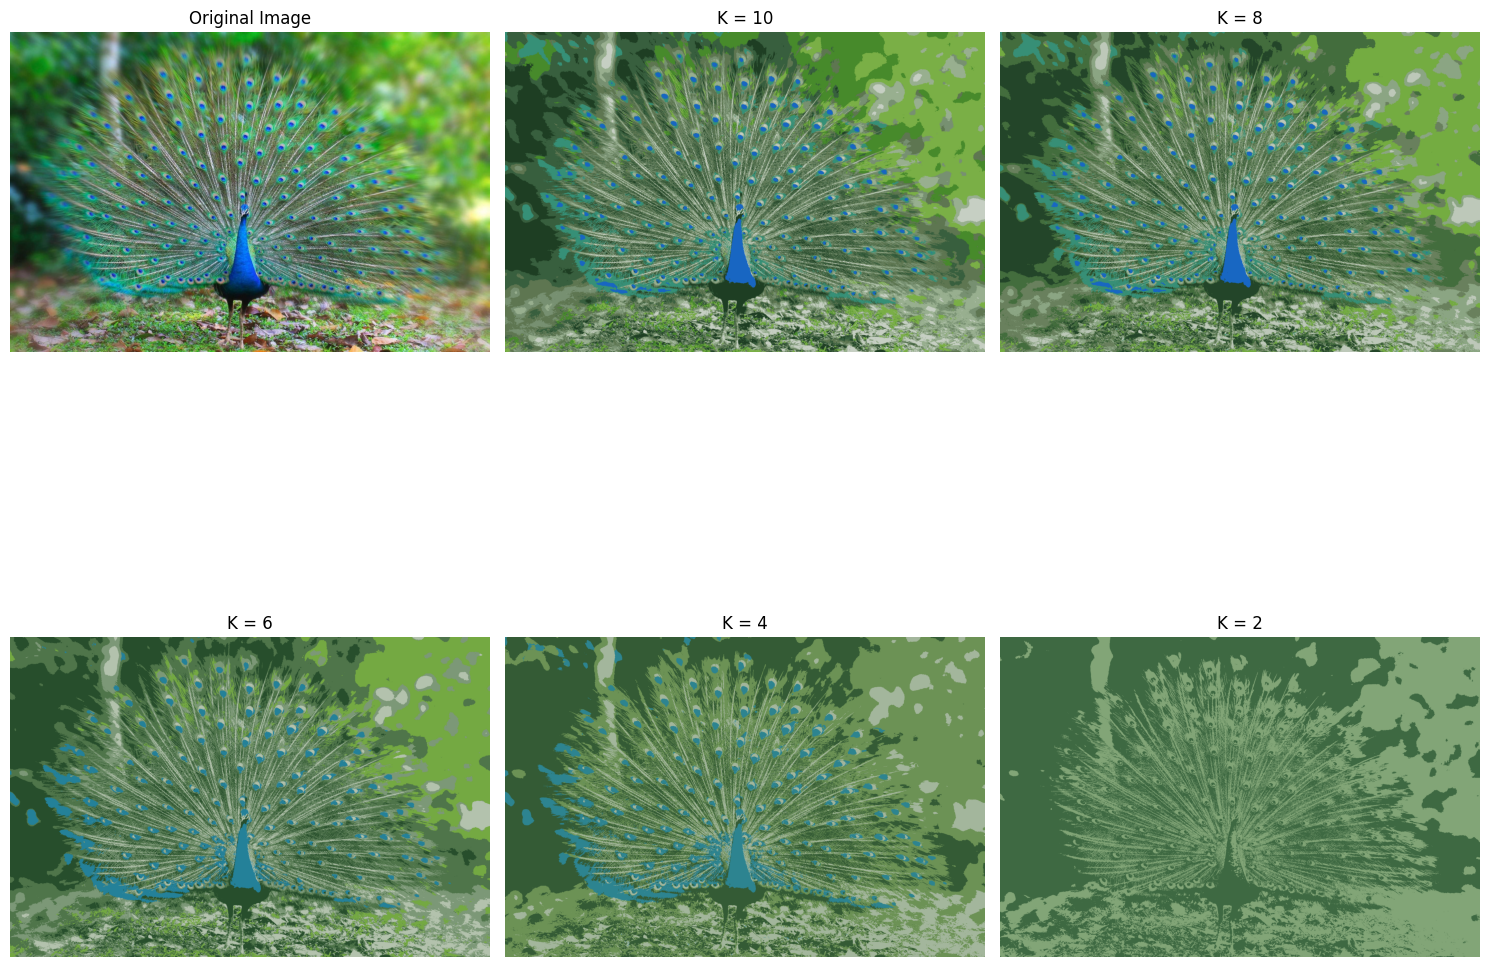

In [37]:
# TODO: train voor elk aantal kleuren een KMeans (random_state=42, n_init=10)
# op X, vervang elke pixel door de centroidkleur van zijn cluster en hervorm
# terug naar image.shape. Bewaar alles in segmented_imgs (volgorde van n_colors).
n_colors = (10, 8, 6, 4, 2)
segmented_imgs = []
for n_clusters in n_colors:
    k_means = KMeans(n_clusters=n_clusters,random_state=42,n_init=10)
    k_means.fit(X)
    k_means_labels = k_means.predict(X)
    segmented_img = k_means.cluster_centers_[k_means_labels]  # aan te passen
    segmented_imgs.append(segmented_img.reshape(image.shape))
figure_size = 15
plt.figure(figsize=(figure_size, figure_size))

plt.subplot(2, 3, 1)
plt.imshow(image)
plt.title('Original Image')
plt.axis('off')

for i in range(len(n_colors)):
    plt.subplot(2, 3, i + 2)
    plt.imshow(segmented_imgs[i].astype(np.uint8))
    plt.title('K = %i' % n_colors[i])
    plt.axis('off')

plt.tight_layout()
plt.show()

## Oefening 3 — KMeans vs DBSCAN op Iris

De Iris-dataset bevat 3 soorten die in de feature-ruimte goed gescheiden, **bolvormige** clusters van **gelijkaardige dichtheid** vormen.

Pas zowel KMeans (verschillende `k`) als DBSCAN (verschillende `eps`/`min_samples`) toe op de **gestandaardiseerde** data en vergelijk met de silhouette score. Bewaar je gekozen `k` in `best_k_iris` en de hoogste silhouette in `silhouette_iris`. Beantwoord daarna vraag 1 in `antwoord_iris`.

In [46]:
import numpy as np
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

iris = load_iris()
data_scaled = StandardScaler().fit_transform(iris.data)

startwaarde = -1

# KMeans testen voor k van 2 tot 5
for k in range(2,5):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    k_means_labels = kmeans.fit_predict(data_scaled)

    score = silhouette_score(data_scaled, k_means_labels)

    if score > startwaarde:
        best_k_iris = k
        silhouette_iris = score
        startwaarde = score

    print(f"Bij k = {k} is de silhouette score {score}")

print(f"Beste KMeans k: {best_k_iris}")
print(f"Beste KMeans silhouette score: {silhouette_iris}")


# DBSCAN testen voor verschillende eps en min_samples
beste_dbscan_score = -1

for d in [0.2, 0.5, 0.8, 1.0]:
    for b in range(2, 6):
        dbscan = DBSCAN(eps=d, min_samples=b)
        dbscan_labels = dbscan.fit_predict(data_scaled)

        # Silhouette score is alleen bruikbaar bij minstens 2 clusters
        # en minder clusters dan het aantal datapunten
        aantal_clusters = len(set(dbscan_labels) - {-1})

        if 2 <= aantal_clusters < len(data_scaled):
            score = silhouette_score(data_scaled, dbscan_labels)

            if score > beste_dbscan_score:
                beste_dbscan_score = score
                best_e_iris = d
                best_b_iris = b

            print(f"Bij eps = {d} en min_samples = {b} is de silhouette score {score}")
        else:
            print(f"Bij eps = {d} en min_samples = {b} kan de silhouette score niet berekend worden.")

if beste_dbscan_score > -1:
    print(f"Beste DBSCAN eps: {best_e_iris}")
    print(f"Beste DBSCAN min_samples: {best_b_iris}")
    print(f"Beste DBSCAN silhouette score: {beste_dbscan_score}")
else:
    print("Geen geldige DBSCAN-configuratie gevonden.")

Bij k = 2 is de silhouette score 0.5817500491982808
Bij k = 3 is de silhouette score 0.45994823920518635
Bij k = 4 is de silhouette score 0.38694104154427816
Beste KMeans k: 2
Beste KMeans silhouette score: 0.5817500491982808
Bij eps = 0.2 en min_samples = 2 is de silhouette score -0.37112581511214593
Bij eps = 0.2 en min_samples = 3 is de silhouette score 0.08705841329683042
Bij eps = 0.2 en min_samples = 4 is de silhouette score 0.02514589229455723
Bij eps = 0.2 en min_samples = 5 kan de silhouette score niet berekend worden.
Bij eps = 0.5 en min_samples = 2 is de silhouette score 0.11500593389476223
Bij eps = 0.5 en min_samples = 3 is de silhouette score 0.15971036873870176
Bij eps = 0.5 en min_samples = 4 is de silhouette score 0.36457435678297523
Bij eps = 0.5 en min_samples = 5 is de silhouette score 0.35651648142700726
Bij eps = 0.8 en min_samples = 2 is de silhouette score 0.48696338465519584
Bij eps = 0.8 en min_samples = 3 is de silhouette score 0.5216965052515835
Bij eps = 0

## Oefening 4 — KMeans vs DBSCAN op Mall

De Mall-dataset (`data/Mall_Customers.csv`) bevat klanten met `Age`, `Annual Income (k$)` en `Spending Score (1-100)`. De clusters hebben **sterk verschillende dichtheden**, waardoor DBSCAN het vaak moeilijk heeft.

Pas KMeans (verschillende `k`) en DBSCAN (verschillende `eps`/`min_samples`) toe op de **gestandaardiseerde** data en vergelijk met de silhouette score. Bewaar je gekozen `k` in `best_k_mall` en de hoogste silhouette in `silhouette_mall`. Beantwoord daarna vraag 2 in `antwoord_dbscan`.

In [53]:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

mall = pd.read_csv('data/Mall_Customers.csv')
features = mall[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']]
data_scaled = StandardScaler().fit_transform(features)
startwaarde = -1
# TODO: vergelijk KMeans (verschillende k's) met DBSCAN (verschillende
# eps/min_samples) via de silhouette score. Bewaar de gekozen k in best_k_mall
# en de hoogste silhouette in silhouette_mall.
for k in range(2,8):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    k_means_labels_mall = kmeans.fit_predict(data_scaled)

    score = silhouette_score(data_scaled, k_means_labels_mall)

    if score > startwaarde:
        best_k_mall = k
        silhouette_mall = score
        startwaarde = score

    print(f"Bij k = {k} is de silhouette score {score}")

print(f"Beste KMeans k: {best_k_mall}")
print(f"Beste KMeans silhouette score: {silhouette_mall}")


# DBSCAN testen voor verschillende eps en min_samples
beste_dbscan_score = -1

for d in [0.2, 0.4,0.6, 0.8, 1.0]:
    for b in range(1, 20):
        dbscan = DBSCAN(eps=d, min_samples=b)
        dbscan_labels = dbscan.fit_predict(data_scaled)

        # Silhouette score is alleen bruikbaar bij minstens 2 clusters
        # en minder clusters dan het aantal datapunten
        aantal_clusters = len(set(dbscan_labels) - {-1})

        if 2 <= aantal_clusters < len(data_scaled):
            score = silhouette_score(data_scaled, dbscan_labels)

            if score > beste_dbscan_score:
                beste_dbscan_score = score
                best_e_iris = d
                best_b_iris = b

            print(f"Bij eps = {d} en min_samples = {b} is de silhouette score {score}")
if beste_dbscan_score > -1:
    print(f"Beste DBSCAN eps: {best_e_iris}")
    print(f"Beste DBSCAN min_samples: {best_b_iris}")
    print(f"Beste DBSCAN silhouette score: {beste_dbscan_score}")
else:
    print("Geen geldige DBSCAN-configuratie gevonden.")
        
best_k_mall = 5
silhouette_mall = 0.0

Bij k = 2 is de silhouette score 0.33547192894004574
Bij k = 3 is de silhouette score 0.357793388710272
Bij k = 4 is de silhouette score 0.4039582785148566
Bij k = 5 is de silhouette score 0.41664341513732767
Bij k = 6 is de silhouette score 0.4284167762892593
Bij k = 7 is de silhouette score 0.417231894954916
Beste KMeans k: 6
Beste KMeans silhouette score: 0.4284167762892593
Bij eps = 0.2 en min_samples = 1 is de silhouette score 0.12991759263057104
Bij eps = 0.2 en min_samples = 2 is de silhouette score -0.26228579920933304
Bij eps = 0.2 en min_samples = 3 is de silhouette score -0.32831346361113956
Bij eps = 0.2 en min_samples = 4 is de silhouette score -0.3399135394830671
Bij eps = 0.4 en min_samples = 1 is de silhouette score 0.11756616756127167
Bij eps = 0.4 en min_samples = 2 is de silhouette score 0.1604429394842519
Bij eps = 0.4 en min_samples = 3 is de silhouette score 0.15130743739735508
Bij eps = 0.4 en min_samples = 4 is de silhouette score 0.11311020759466783
Bij eps = 0

## Meerkeuzevragen

### Vraag 1 — Iris
Op de Iris-dataset haalt KMeans een veel hogere silhouette score dan DBSCAN. Wat is de belangrijkste reden?

- **A)** De clusters zijn bolvormig en hebben een gelijkaardige dichtheid, waarvoor KMeans goed geschikt is; DBSCAN kampt met de dichtheidsverschillen.
- **B)** KMeans werkt zonder features te standaardiseren.
- **C)** DBSCAN kan nooit meer dan 2 clusters vinden.
- **D)** KMeans kent het aantal clusters op voorhand, en dat is altijd beter.

Bewaar je antwoord (`"A"`, `"B"`, `"C"` of `"D"`) in `antwoord_iris`.

### Vraag 2 — DBSCAN
Wanneer is DBSCAN een betere keuze dan KMeans?

- **A)** Wanneer de clusters een onregelmatige, niet-bolvormige vorm hebben of er outliers/ruis zijn.
- **B)** Wanneer alle clusters bolvormig en even groot zijn.
- **C)** Wanneer je altijd precies `k` clusters nodig hebt.
- **D)** Wanneer de dataset klein is en je snel wilt clusteren.

Bewaar je antwoord (`"A"`, `"B"`, `"C"` of `"D"`) in `antwoord_dbscan`.

In [ ]:
# Vraag 1: antwoord_iris = "A", "B", "C" of "D"
antwoord_iris = "A"

# Vraag 2: antwoord_dbscan = "A", "B", "C" of "D"
antwoord_dbscan = "A"
